## EDA: SPARCS 2024 Length of Stay

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

df = pd.read_parquet(Path("../data/raw/sparcs_2024_raw.parquet"))

# target: "120+" is top-coded, treated as 120
df["los"] = pd.to_numeric(df["length_of_stay"].str.replace("+", "", regex=False))

# features: leakage columns and text descriptions of code columns are excluded
CAT_FEATURES = [
    "health_service_area", "hospital_county", "operating_certificate_number", "permanent_facility_id",
    "age_group", "zip_code", "gender", "race", "ethnicity",
    "type_of_admission", "emergency_department_indicator", "ccsr_diagnosis_code",
    "payment_typology_1", "payment_typology_2", "payment_typology_3",
]
df["birth_weight"] = pd.to_numeric(df["birth_weight"], errors="coerce")  # "UNKN" -> NaN
df[CAT_FEATURES] = df[CAT_FEATURES].fillna("Missing")

### Target: length of stay

In [2]:
df["los"].describe(percentiles=[.5, .75, .9, .95, .99]).round(2)

count    2196737.00
mean           5.81
std            8.83
min            1.00
50%            3.00
75%            6.00
90%           12.00
95%           19.00
99%           42.00
max          120.00
Name: los, dtype: float64

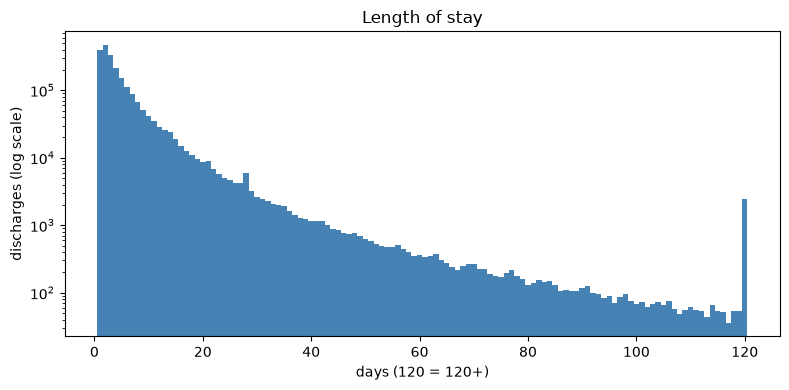

In [3]:
plt.figure(figsize=(8, 4))
plt.hist(df["los"], bins=np.arange(0.5, 121.5, 1), color="steelblue")
plt.yscale("log")
plt.title("Length of stay")
plt.xlabel("days (120 = 120+)")
plt.ylabel("discharges (log scale)")
plt.tight_layout()
plt.show()

### Features

#### Hospital

`hospital_county` and `operating_certificate_number` are not plotted: `hospital_county` determines `health_service_area`, and `operating_certificate_number` is one-to-one with `permanent_facility_id`.

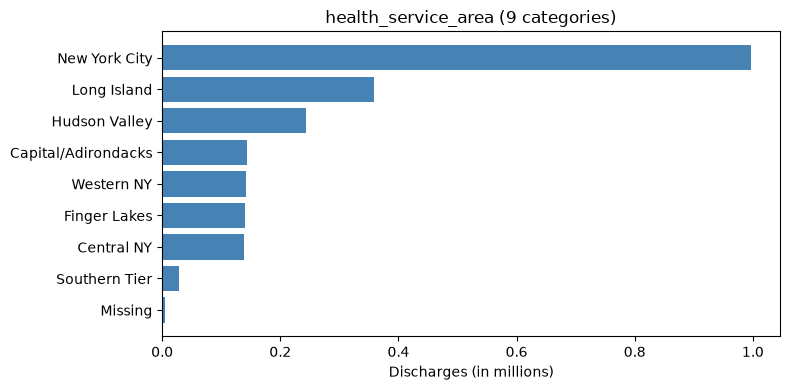

In [4]:
col = "health_service_area"
counts = df[col].value_counts()

plt.figure(figsize=(8, 4))
plt.barh(counts.index[::-1], counts.values[::-1] / 1e6, color="steelblue")
plt.title(f"{col} ({df[col].nunique()} categories)")
plt.xlabel("Discharges (in millions)")
plt.tight_layout()
plt.show()

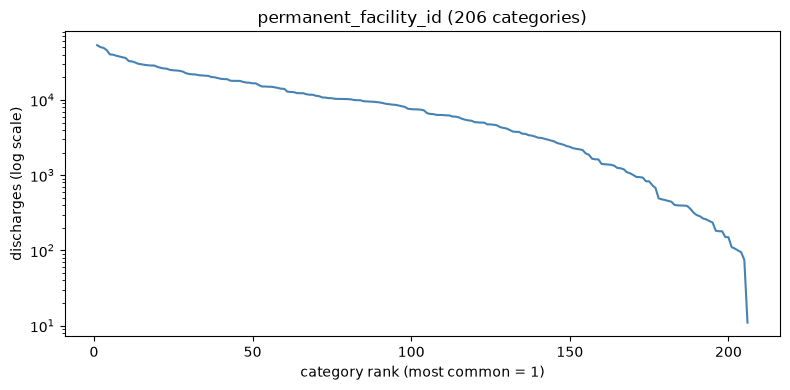

In [5]:
col = "permanent_facility_id"
counts = df[col].value_counts()

plt.figure(figsize=(8, 4))
plt.plot(np.arange(1, len(counts) + 1), counts.values, color="steelblue")
plt.yscale("log")
plt.title(f"{col} ({len(counts)} categories)")
plt.xlabel("category rank (most common = 1)")
plt.ylabel("discharges (log scale)")
plt.tight_layout()
plt.show()

#### Patient

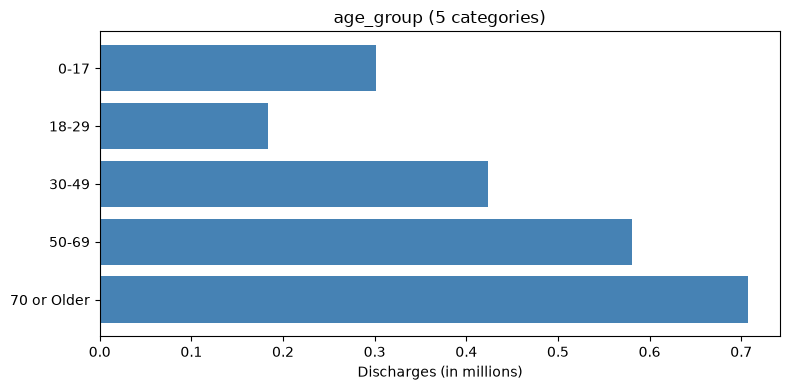

In [6]:
col = "age_group"
counts = df[col].value_counts().reindex(["0-17", "18-29", "30-49", "50-69", "70 or Older"])

plt.figure(figsize=(8, 4))
plt.barh(counts.index[::-1], counts.values[::-1] / 1e6, color="steelblue")
plt.title(f"{col} ({df[col].nunique()} categories)")
plt.xlabel("Discharges (in millions)")
plt.tight_layout()
plt.show()

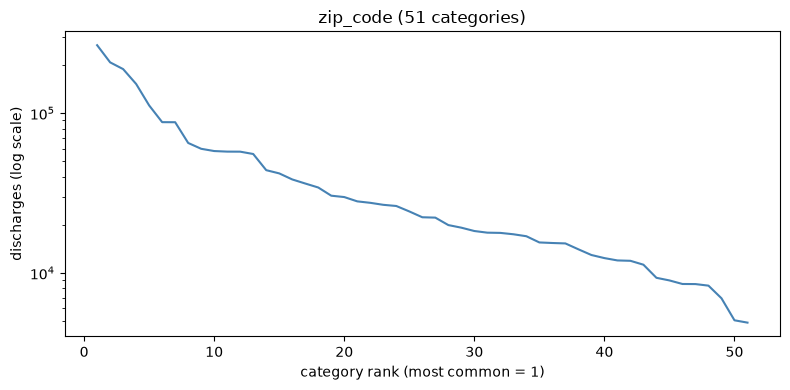

In [7]:
col = "zip_code"
counts = df[col].value_counts()

plt.figure(figsize=(8, 4))
plt.plot(np.arange(1, len(counts) + 1), counts.values, color="steelblue")
plt.yscale("log")
plt.title(f"{col} ({len(counts)} categories)")
plt.xlabel("category rank (most common = 1)")
plt.ylabel("discharges (log scale)")
plt.tight_layout()
plt.show()

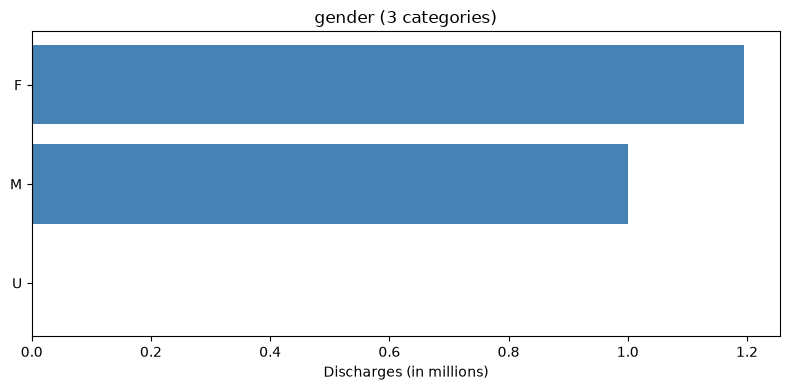

In [8]:
col = "gender"
counts = df[col].value_counts()

plt.figure(figsize=(8, 4))
plt.barh(counts.index[::-1], counts.values[::-1] / 1e6, color="steelblue")
plt.title(f"{col} ({df[col].nunique()} categories)")
plt.xlabel("Discharges (in millions)")
plt.tight_layout()
plt.show()

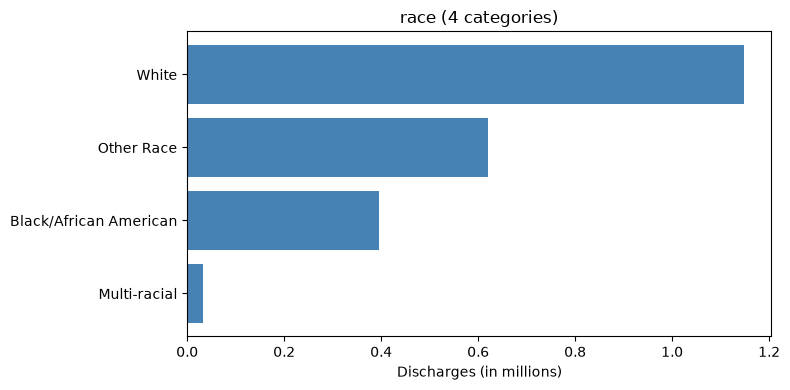

In [9]:
col = "race"
counts = df[col].value_counts()

plt.figure(figsize=(8, 4))
plt.barh(counts.index[::-1], counts.values[::-1] / 1e6, color="steelblue")
plt.title(f"{col} ({df[col].nunique()} categories)")
plt.xlabel("Discharges (in millions)")
plt.tight_layout()
plt.show()

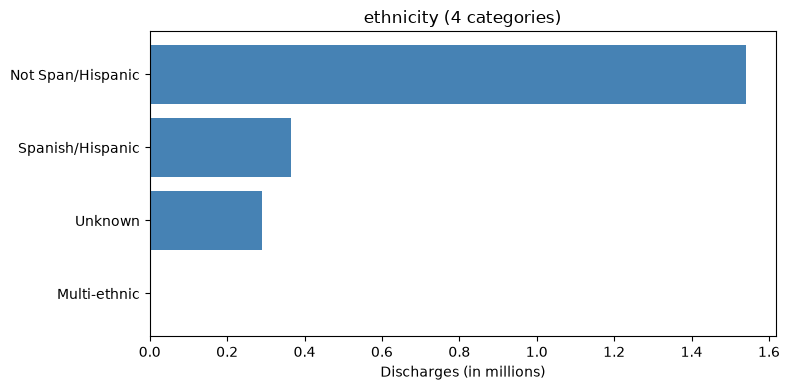

In [10]:
col = "ethnicity"
counts = df[col].value_counts()

plt.figure(figsize=(8, 4))
plt.barh(counts.index[::-1], counts.values[::-1] / 1e6, color="steelblue")
plt.title(f"{col} ({df[col].nunique()} categories)")
plt.xlabel("Discharges (in millions)")
plt.tight_layout()
plt.show()

#### Admission and diagnosis

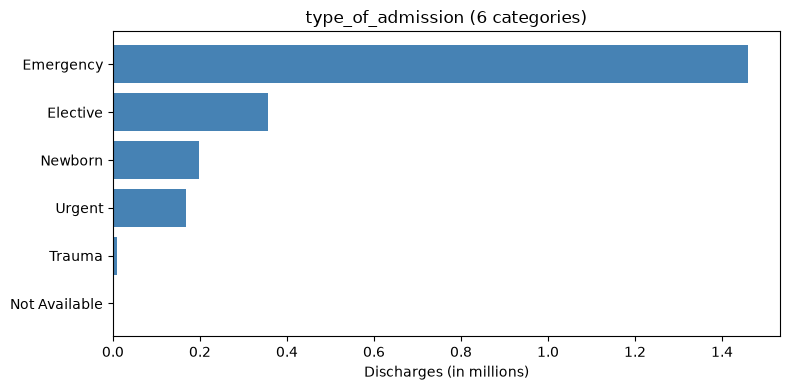

In [11]:
col = "type_of_admission"
counts = df[col].value_counts()

plt.figure(figsize=(8, 4))
plt.barh(counts.index[::-1], counts.values[::-1] / 1e6, color="steelblue")
plt.title(f"{col} ({df[col].nunique()} categories)")
plt.xlabel("Discharges (in millions)")
plt.tight_layout()
plt.show()

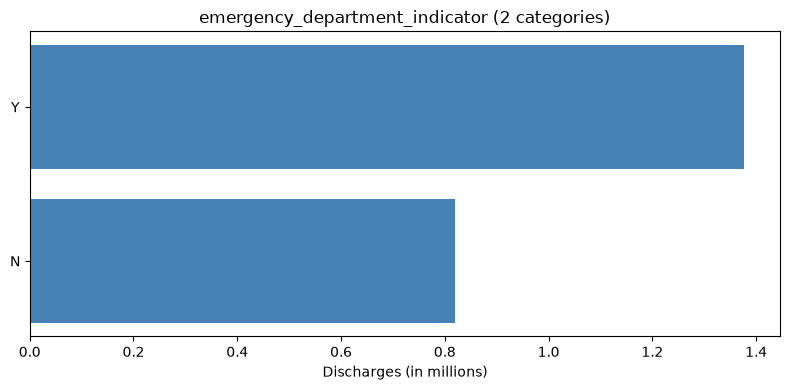

In [12]:
col = "emergency_department_indicator"
counts = df[col].value_counts()

plt.figure(figsize=(8, 4))
plt.barh(counts.index[::-1], counts.values[::-1] / 1e6, color="steelblue")
plt.title(f"{col} ({df[col].nunique()} categories)")
plt.xlabel("Discharges (in millions)")
plt.tight_layout()
plt.show()

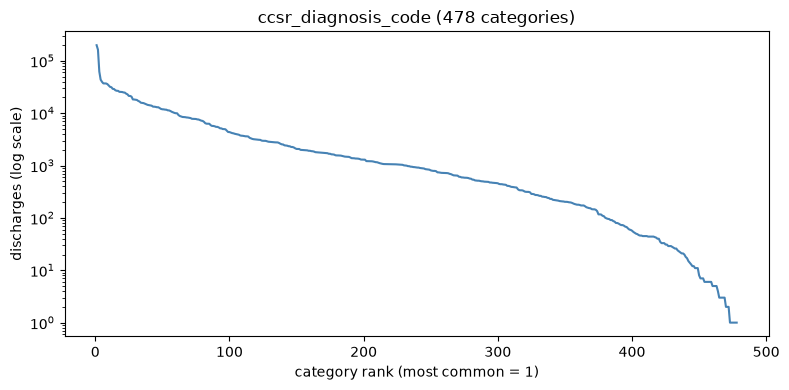

In [13]:
col = "ccsr_diagnosis_code"
counts = df[col].value_counts()

plt.figure(figsize=(8, 4))
plt.plot(np.arange(1, len(counts) + 1), counts.values, color="steelblue")
plt.yscale("log")
plt.title(f"{col} ({len(counts)} categories)")
plt.xlabel("category rank (most common = 1)")
plt.ylabel("discharges (log scale)")
plt.tight_layout()
plt.show()

#### Payment

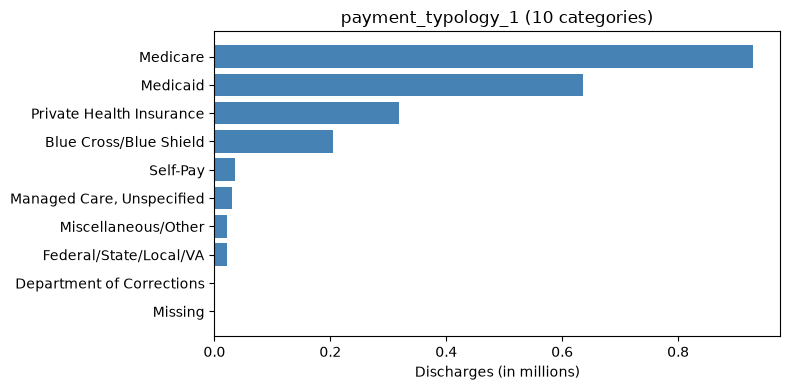

In [14]:
col = "payment_typology_1"
counts = df[col].value_counts()

plt.figure(figsize=(8, 4))
plt.barh(counts.index[::-1], counts.values[::-1] / 1e6, color="steelblue")
plt.title(f"{col} ({df[col].nunique()} categories)")
plt.xlabel("Discharges (in millions)")
plt.tight_layout()
plt.show()

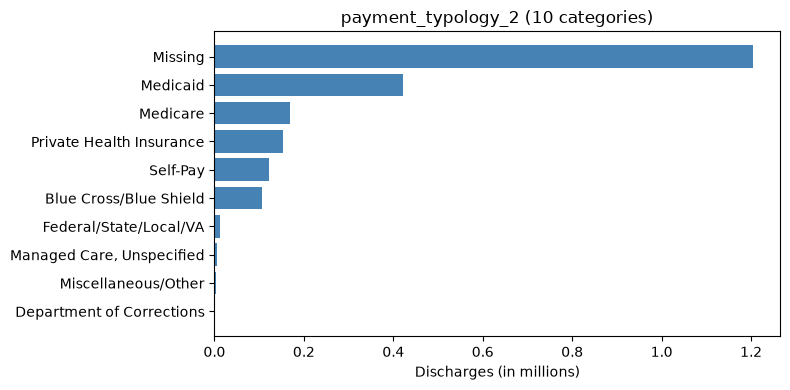

In [15]:
col = "payment_typology_2"
counts = df[col].value_counts()

plt.figure(figsize=(8, 4))
plt.barh(counts.index[::-1], counts.values[::-1] / 1e6, color="steelblue")
plt.title(f"{col} ({df[col].nunique()} categories)")
plt.xlabel("Discharges (in millions)")
plt.tight_layout()
plt.show()

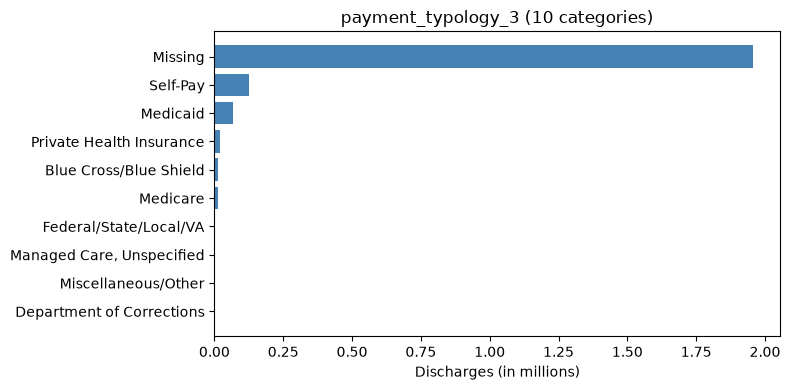

In [16]:
col = "payment_typology_3"
counts = df[col].value_counts()

plt.figure(figsize=(8, 4))
plt.barh(counts.index[::-1], counts.values[::-1] / 1e6, color="steelblue")
plt.title(f"{col} ({df[col].nunique()} categories)")
plt.xlabel("Discharges (in millions)")
plt.tight_layout()
plt.show()

#### Birth weight

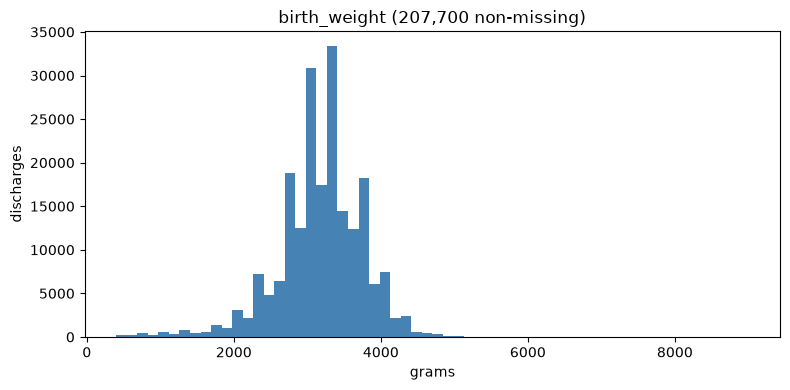

In [17]:
plt.figure(figsize=(8, 4))
plt.hist(df["birth_weight"].dropna(), bins=60, color="steelblue")
plt.title(f"birth_weight ({df['birth_weight'].notna().sum():,} non-missing)")
plt.xlabel("grams")
plt.ylabel("discharges")
plt.tight_layout()
plt.show()

### Correlation with the target

Categorical features: correlation ratio (eta, 0 to 1) between the feature and length of stay. `birth_weight`: absolute Spearman correlation.

In [ ]:
corr = {}
for c in CAT_FEATURES:
    g = df.groupby(c)["los"]#the length of stay list for each category
    between = (g.size() * (g.mean() - df["los"].mean()) ** 2).sum()
    corr[c] = np.sqrt(between / ((df["los"] - df["los"].mean()) ** 2).sum())

bw = df.dropna(subset=["birth_weight"])
corr["birth_weight"] = abs(bw["birth_weight"].rank().corr(bw["los"].rank()))

corr = pd.Series(corr).sort_values(ascending=False)
corr.round(3).to_frame("association with los")

,association with los
ccsr_diagnosis_code,0.345
permanent_facility_id,0.220
birth_weight,0.203
operating_certificate_number,0.190
age_group,0.110
payment_typology_1,0.103
type_of_admission,0.102
payment_typology_2,0.076
hospital_county,0.067
emergency_department_indicator,0.067


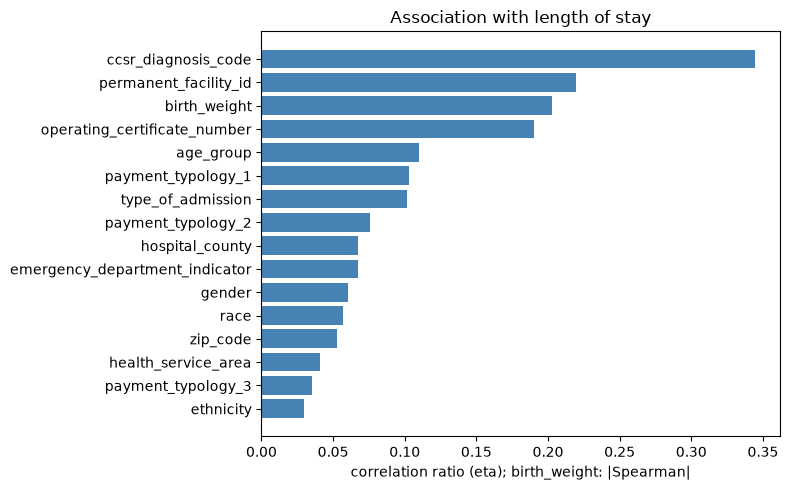

In [19]:
plt.figure(figsize=(8, 5))
plt.barh(corr.index[::-1], corr.values[::-1], color="steelblue")
plt.title("Association with length of stay")
plt.xlabel("correlation ratio (eta); birth_weight: |Spearman|")
plt.tight_layout()
plt.show()

#### Features with association >= 0.1

`operating_certificate_number` (0.19) is left out because it is one-to-one with `permanent_facility_id`.

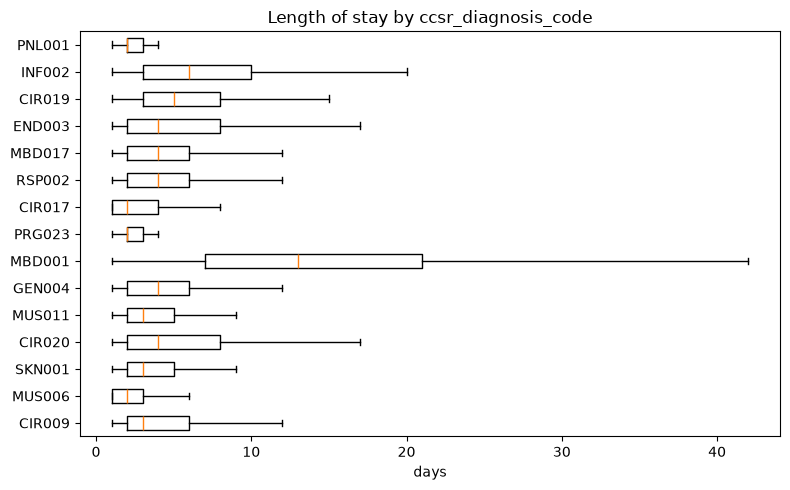

In [20]:
col = "ccsr_diagnosis_code"
order = df[col].value_counts().index[:15]  # top 15 categories
groups = [df.loc[df[col] == c, "los"] for c in order]

plt.figure(figsize=(8, 5))
plt.boxplot(groups[::-1], orientation="horizontal", tick_labels=list(order)[::-1], showfliers=False)
plt.title(f"Length of stay by {col}")
plt.xlabel("days")
plt.tight_layout()
plt.show()

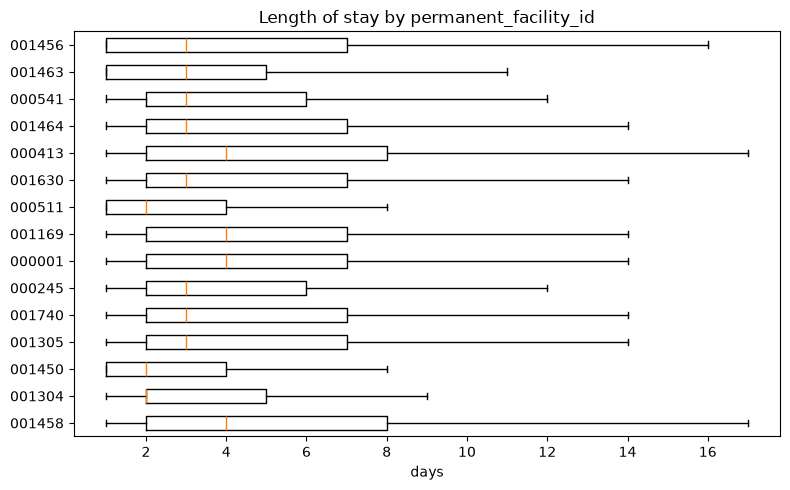

In [21]:
col = "permanent_facility_id"
order = df[col].value_counts().index[:15]  # top 15 categories
groups = [df.loc[df[col] == c, "los"] for c in order]

plt.figure(figsize=(8, 5))
plt.boxplot(groups[::-1], orientation="horizontal", tick_labels=list(order)[::-1], showfliers=False)
plt.title(f"Length of stay by {col}")
plt.xlabel("days")
plt.tight_layout()
plt.show()

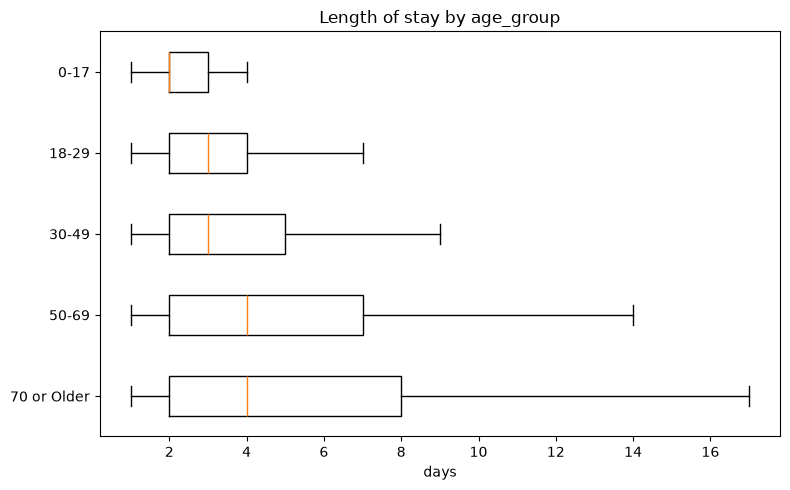

In [22]:
col = "age_group"
order = ["0-17", "18-29", "30-49", "50-69", "70 or Older"]
groups = [df.loc[df[col] == c, "los"] for c in order]

plt.figure(figsize=(8, 5))
plt.boxplot(groups[::-1], orientation="horizontal", tick_labels=list(order)[::-1], showfliers=False)
plt.title(f"Length of stay by {col}")
plt.xlabel("days")
plt.tight_layout()
plt.show()

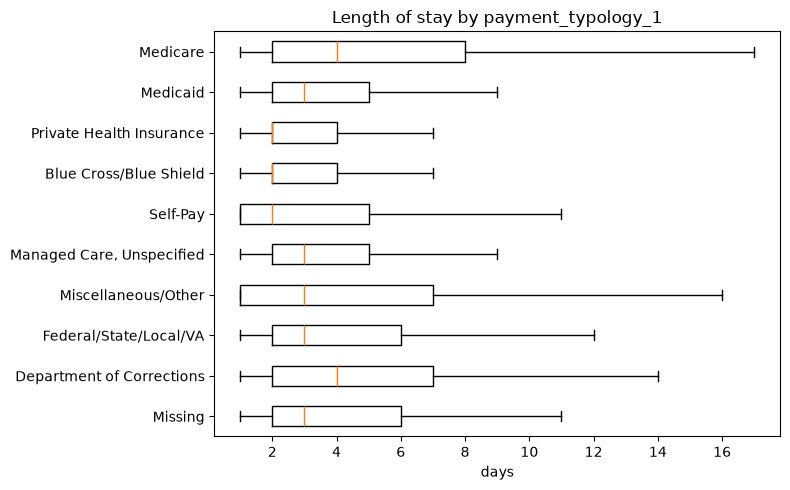

In [23]:
col = "payment_typology_1"
order = df[col].value_counts().index[:15]  # top 15 categories
groups = [df.loc[df[col] == c, "los"] for c in order]

plt.figure(figsize=(8, 5))
plt.boxplot(groups[::-1], orientation="horizontal", tick_labels=list(order)[::-1], showfliers=False)
plt.title(f"Length of stay by {col}")
plt.xlabel("days")
plt.tight_layout()
plt.show()

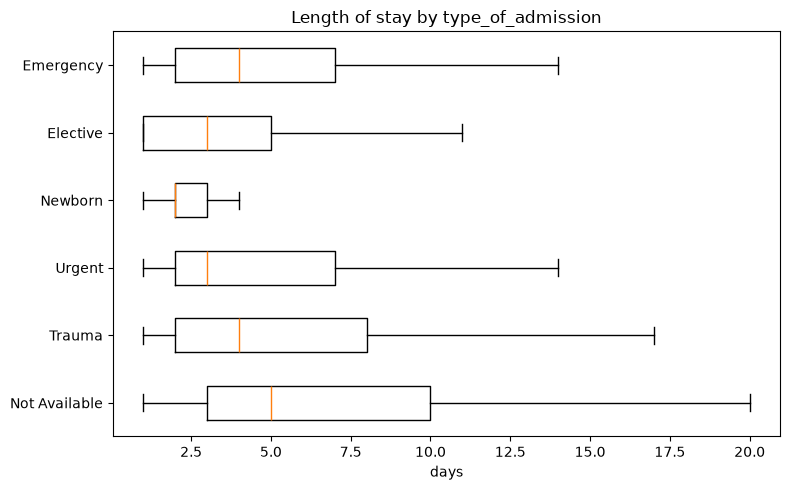

In [24]:
col = "type_of_admission"
order = df[col].value_counts().index[:15]  # top 15 categories
groups = [df.loc[df[col] == c, "los"] for c in order]

plt.figure(figsize=(8, 5))
plt.boxplot(groups[::-1], orientation="horizontal", tick_labels=list(order)[::-1], showfliers=False)
plt.title(f"Length of stay by {col}")
plt.xlabel("days")
plt.tight_layout()
plt.show()

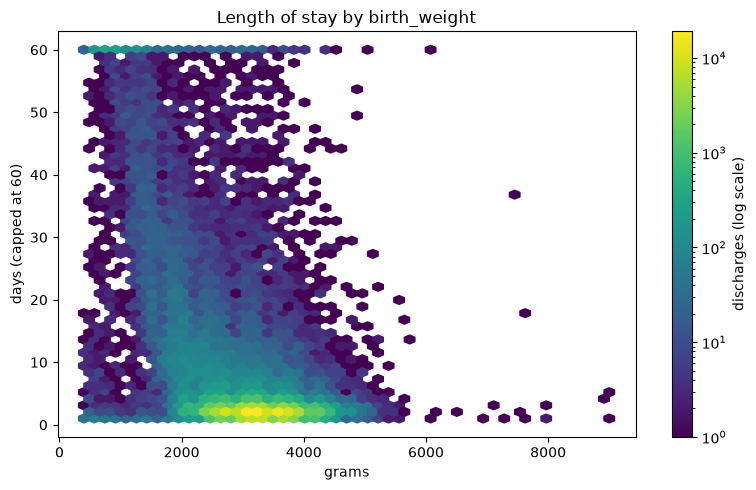

In [25]:
plt.figure(figsize=(8, 5))
plt.hexbin(bw["birth_weight"], bw["los"].clip(upper=60), gridsize=50, bins="log", cmap="viridis", mincnt=1)
plt.colorbar(label="discharges (log scale)")
plt.title("Length of stay by birth_weight")
plt.xlabel("grams")
plt.ylabel("days (capped at 60)")
plt.tight_layout()
plt.show()